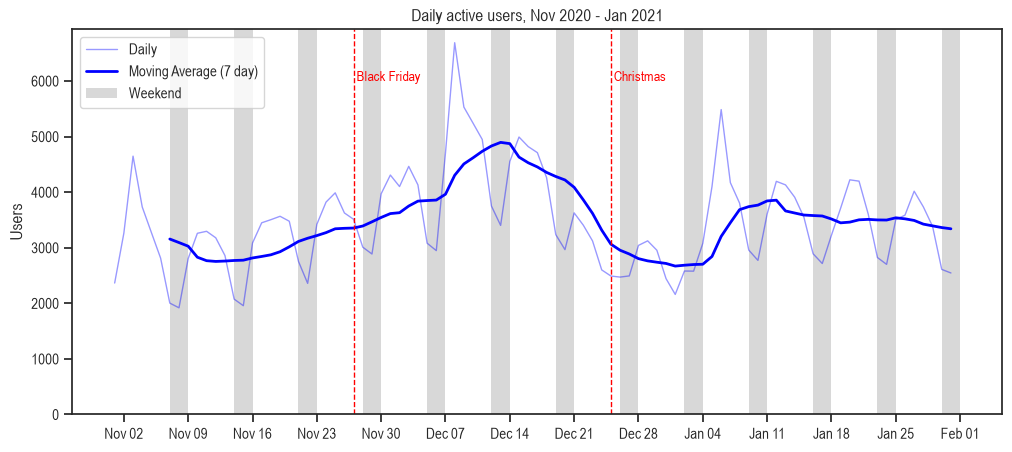

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Load the data
df = pd.read_csv("../data/01_daily_users.csv", parse_dates=["event_day"])

# Calculate moving average
df["moving_average"] = df["users"].rolling(7).mean()

# Graph settings
sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(12, 5))

# Base line graph
sns.lineplot(data=df, x="event_day", y='users', ax=ax, color="blue", alpha=0.4, linewidth=1, label="Daily")
sns.lineplot(data=df, x="event_day", y='moving_average', ax=ax, color="blue", alpha=1, linewidth=2, label="Moving Average (7 day)")

# Show holidays
ax.axvline(pd.Timestamp("2020-11-27"), color="red", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2020-11-27"), 6000, " Black Friday", color="red", fontsize=10)
ax.axvline(pd.Timestamp("2020-12-25"), color="red", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2020-12-25"), 6000, " Christmas", color="red", fontsize=10)

# Mark weekends
saturdays = df.loc[df["event_day"].dt.dayofweek == 5, "event_day"]
for i, sat in enumerate(saturdays):
  ax.axvspan(sat, sat+ pd.Timedelta(days=2), color="gray", alpha=0.3, linewidth=0, label="Weekend" if i == 0 else None)

# Ticks on mondays
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

# Labels
ax.set_title("Daily active users, Nov 2020 - Jan 2021")
ax.set_xlabel(None)
ax.set_ylabel("Users")
ax.set_ylim(bottom=0)
ax.legend()

plt.savefig("../img/01_daily_users.png", dpi=150, bbox_inches="tight")
plt.show()

## Findings

- Activity peaks in the first two weeks of December, with ~4,900 daily users (7-day avg) vs ~2,800 in early November.
- Weekends have ~30% fewer users than weekdays.
- Black Friday doesn't seem to affect activity.
- Activity drops from Dec 18 and bottoms out at ~2,700 daily users between Christmas and New Year.
- Activity recovers in the week after New Year: from ~2,700 to ~3,850 daily users (7-day avg) between Jan 4 and Jan 11. It then stays around ~3,500, higher than in November.